# Empirical Parameters Calibration for Activity Level distribution


## Folder placement

- **Current location**: `analyses/calibration/activity/`

## 1) Data used

Describe the empirical data source(s) in enough detail for a future reader to obtain or reproduce it.

- **Dataset name or source**: Bluesky firehose
- **Time range**: 2025-05-01
- **Access / documentation link**: Data collection was done with [`osome-iu/osome-bluesky-streamer`](https://github.com/osome-iu/osome-bluesky-streamer), an archive can be requested by contacting [OSoMe IU](https://osome.iu.edu/resources/data-resources).
- **Raw files / tables used**: `2025-05-01.json.gz`
- **Preprocessing steps**: 
    1. Read `type` and `action` from each event in the firehose
    2. Store with `author`, timestamp, and is_self

In [ ]:
import gzip
import json
import logging

from tqdm import tqdm
from datetime import datetime

def get_rtype(rec: dict) -> str | None:
    return rec.get("type") or rec.get("$type")

def extract_embed_post_uri(rec: dict) -> str | None:
    embed = rec.get("embed")
    if not isinstance(embed, dict):
        return None

    record = embed.get("record")
    if isinstance(record, dict):
        inner = record.get("record") if isinstance(record.get("record"), dict) else record
        uri = inner.get("uri") if isinstance(inner, dict) else None
        if isinstance(uri, str) and "/app.bsky" in uri:
            return uri

    return None

def extract_did(uri):
    return uri.split("/")[2]

def classify_post(rec: dict) -> str:
    if rec.get("reply"):
        return "reply"

    embed = rec.get("embed")
    if isinstance(embed, dict):
        etype = embed.get("$type", "")
        if etype in ("app.bsky.embed.record", "app.bsky.embed.recordWithMedia"):
            return "quote"
        if "record" in embed:
            return "quote"

    return "post"

def classify_action(rec: dict, rtype: str | None = None) -> str | None:
    rtype = rtype or get_rtype(rec)
    if rtype == "app.bsky.feed.like":
        return "like"
    if rtype == "app.bsky.feed.repost":
        return "repost"
    if rtype == "app.bsky.feed.post":
        return classify_post(rec)
    return None

def is_self(event, event_type):
    if event_type == "quote":
        return extract_did(extract_embed_post_uri(event)) == event["author"]
    
    if event_type == "reply":
        return extract_did(event["reply"]["parent"]["uri"]) == event["author"]
    
    if event_type == "repost" or event_type == "like":
        return extract_did(event["subject"]["uri"]) == event["author"]
    
    return False

def get_timestamps(path):
    dates = []
    types = []
    actions = []
    dids = []
    is_selfs = []
    with gzip.open(path, "rt") as f:
        for line in tqdm(f):
            try:
                event = json.loads(line)

                ts = datetime.strptime(event["commit_time_str"], "%Y-%m-%dT%H:%M:%S.%fZ")
                dates.append(int(ts.timestamp() * 1000))

                type_ = classify_action(event)
                types.append(type_)
                actions.append(event["action"])
                dids.append(event["author"])

                is_selfs.append(is_self(event, type_) if event["action"] == "create" else None)


            except json.JSONDecodeError as e:
                logging.debug(f"Error in {path}:\n{e}")

    return dates, types, actions, dids, is_selfs

path = "YOUR_PATH_HERE/2025-05-01.json.gz"

timestamps, types, actions, dids, is_selfs = get_timestamps(path)

with gzip.open("timestamps_bsky_users.csv.gz", "wt") as f:
    f.write(f"timestamp,type,action,did,is_self\n")
    for ts, ty, action, did, iss in zip(timestamps, types, actions, dids, is_selfs):
        f.write(f"{ts},{ty},{action},{did},{iss}\n")

## 2) New feature contribution

Explain what new feature this calibration adds and where it lives in the codebase.

- **Component**: `power_law_activity`, `power_law_exponent`
- **What it adds**: Allows for sampling the distribution of event types (post, repost, like, reply, quote) for each user.
- **Code location**: `libs/simsom/subcomponents/setup_db.py`
- **Design rationale**: Although there is a slight correlation between activity level and the distribution, this is ignored for simplicity.


## 2b) References & provenance

Make the calibration traceable to specific code and design. Complete one or more of items below.

- **Repo + branch/tag**: TODO (e.g., `main`, `feature/clock-calibration`, release tag)
- **Commit SHA(s)**: TODO (full 40-char SHA)
- **Pull request / issue**: https://github.com/osome-iu/social-media-simulator/issues/109, https://github.com/osome-iu/social-media-simulator/issues/121


## 3) Analysis / calibration method

Document how you transform the data into model parameters or behaviors.

- **Features extracted**: Per-user activity level from firehose events and number of self-actions per user.
- **Estimation / fitting**: For activity distribution, we use `curve_fit` to fit a power law in log-log space. For runtime analysis, we use `timeit`.
- **Validation**: Line plots of activity level vs probability of that activity level.

In [ ]:
import pandas as pd

df = pd.read_csv("timestamps_bsky_users.csv.gz", engine="pyarrow", usecols=["action", "did", "is_self"])
df = df[df["action"] == "create"]

df

,action,did,is_self
0,create,did:plc:65dh52hlkjx5fiolqii7vbov,False
1,create,did:plc:rjhmgjwpshhm5fbvu3obzjox,False
2,create,did:plc:i5xljap2s26br3gobibv5erp,False
3,create,did:plc:hoggkvllepdburz27lrs4k7q,False
4,create,did:plc:rrqtg4ydogwtgw3uq4rhhjkw,False
...,...,...,...
41174521,create,did:plc:w6r6glo47lxhven67af72vxm,False
41174522,create,did:plc:4kyfqilr7azavvpmkpj5nppa,True
41174523,create,did:plc:avwklydgsfzvhamnq4nk5pkp,False
41174524,create,did:plc:5n7vjm47wfo3dibmkfrk3cri,False


In [2]:
self_counts = df.dropna(subset=["is_self"]).groupby("did")["is_self"].agg(is_self="sum", total="count")

self_counts["ratio"] = self_counts["is_self"] / self_counts["total"]

final_count = self_counts.loc[self_counts["total"] > 0, "ratio"].tolist()

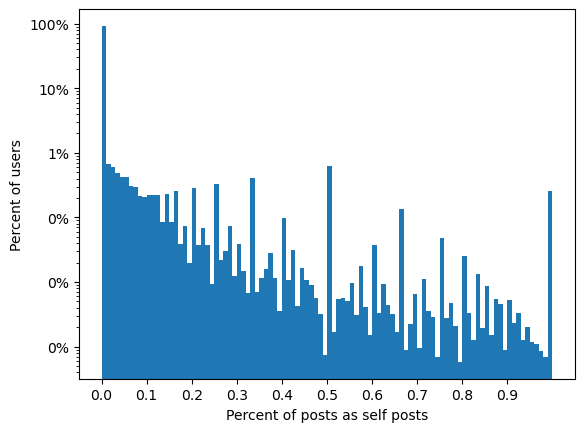

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np

plt.hist(final_count, bins=100, weights=np.ones(len(final_count)) / len(final_count),)
plt.xticks(np.arange(0, 1, 0.1))
plt.yscale("log")
plt.xlabel("Percent of posts as self posts")
plt.ylabel("Percent of users")

plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

In [5]:
counts = df.groupby('did').size()

counts = sorted(counts.tolist())
filter_idx = int(len(counts) * 0.98)
counts = counts[:filter_idx]
len(counts)

1857296

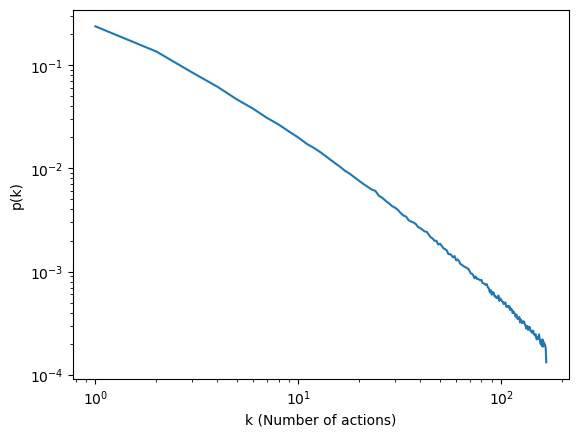

In [6]:
from collections import Counter
import numpy as np

hist = Counter(counts)

x, y = zip(*hist.items())

x = np.array(x)
y = np.array(y)
y = y / np.sum(y)

plt.plot(x, y)
plt.loglog()
plt.xlabel("k (Number of actions)")
plt.ylabel("p(k)")
plt.show()

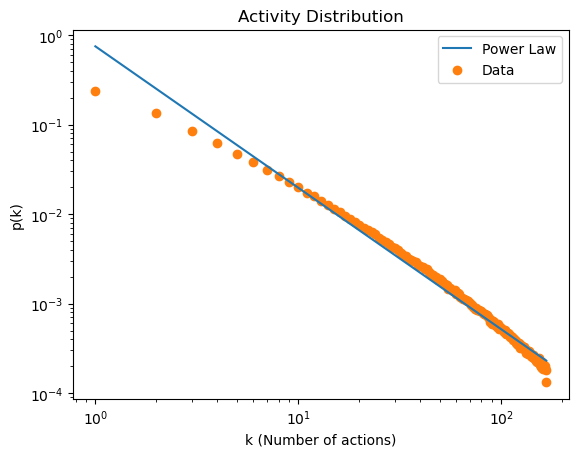

In [7]:
from scipy.optimize import curve_fit

def line(x, m, b):
    return m * x + b

def power_law(x, m, b):
    return np.exp(b) * x ** m

popt, pcov = curve_fit(line, np.log(x), np.log(y), maxfev=2000)

linspace = np.linspace(1, max(x))
plt.plot(linspace, power_law(linspace, *popt), label="Power Law")
plt.scatter(x, y, label="Data", color=plt.cm.tab10(1))
plt.xlabel("k (Number of actions)")
plt.ylabel("p(k)")
plt.legend()
plt.loglog()
plt.title("Activity Distribution")
plt.show()

In [8]:
users = list(range(len(counts)))
activity_levels = np.array(counts)
activity_levels_p = activity_levels / np.sum(activity_levels)
activity_levels_sqrt = np.round(np.sqrt(activity_levels))
activity_levels_p_sqrt = activity_levels_sqrt / np.sum(activity_levels_sqrt)

total_events = np.sum(activity_levels)

print(len(users))

1857296


100%|██████████| 25182653/25182653 [00:13<00:00, 1929824.00it/s]


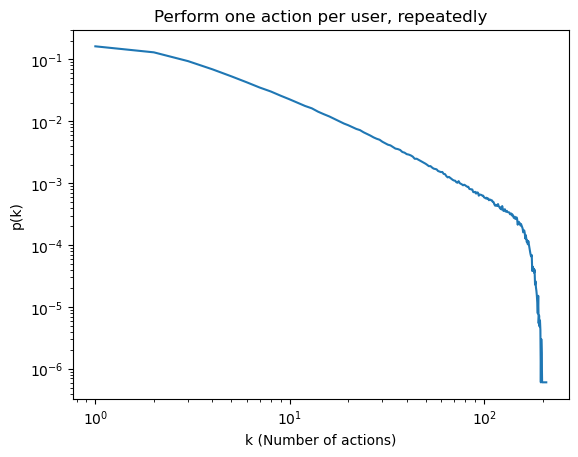

In [ ]:
from tqdm import tqdm

first_counter = Counter()

sample_users = np.random.choice(users, p=activity_levels_p, size=sum(activity_levels))

for u in tqdm(sample_users):
    first_counter[u] += 1

hist = Counter(first_counter.values())

x, y = zip(*sorted(hist.items(), key=lambda x: x[0]))

x = np.array(x)
y = np.array(y)
y = y / np.sum(y)

plt.plot(x, y)
plt.loglog()
plt.title("Perform one action per user, repeatedly")
plt.xlabel("k (Number of actions)")
plt.ylabel("p(k)")
plt.show()

100%|██████████| 1857296/1857296 [00:01<00:00, 1801871.21it/s]


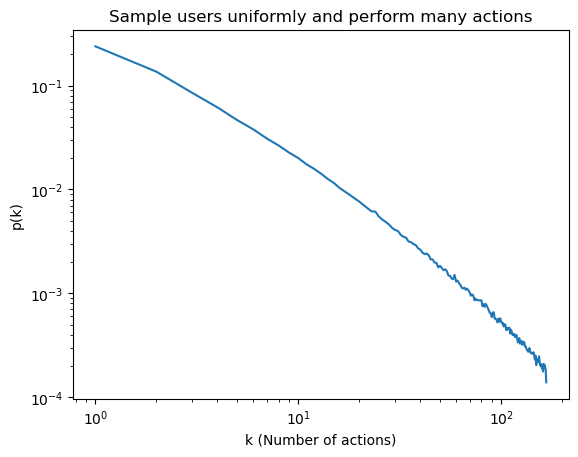

In [ ]:
second_counter = Counter()

sample_users = np.random.choice(users, size=len(users), replace=False)
sample_activity = np.random.choice(activity_levels, size=len(users))

for u, a in tqdm(zip(sample_users, sample_activity), total=len(sample_users)):
    second_counter[u] += a

hist = Counter(second_counter.values())

x, y = zip(*sorted(hist.items(), key=lambda x: x[0]))

x = np.array(x)
y = np.array(y)
y = y / np.sum(y)

plt.plot(x, y)
plt.loglog()
plt.title("Sample users uniformly and perform many actions")
plt.xlabel("k (Number of actions)")
plt.ylabel("p(k)")
plt.show()

100%|██████████| 5233735/5233735 [00:04<00:00, 1254474.40it/s]


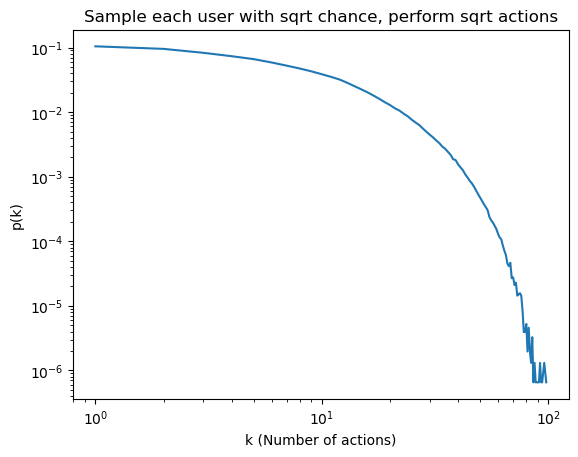

In [ ]:
third_counter = Counter()

sample_users = np.random.choice(users, p=activity_levels_p_sqrt, size=int(np.sum(activity_levels_sqrt)))
sample_activity = np.random.choice(activity_levels_sqrt, size=int(np.sum(activity_levels_sqrt)))

for u, a in tqdm(zip(sample_users, sample_activity), total=len(sample_users)):
    third_counter[u] += a

hist = Counter(third_counter.values())

x, y = zip(*sorted(hist.items(), key=lambda x: x[0]))

x = np.array(x)
y = np.array(y)
y = y / np.sum(y)

plt.plot(x, y)
plt.loglog()
plt.title("Sample each user with sqrt chance, perform sqrt actions")
plt.xlabel("k (Number of actions)")
plt.ylabel("p(k)")
plt.show()

## 3b) Reproduction steps

Provide minimal steps so a new researcher can reproduce the analysis.

1. Ensure `path = "YOUR_PATH_HERE/2025-05-01.json.gz"` is set correctly
2. Run this notebook top-to-bottom to reproduce the plots and fitted parameters.

## 4) Results

To benchmark each method for generating a distribution, we check the time it takes to sample a distribution matching the size of the original dataset (25 million events, 1.9 million users)

In [ ]:
import timeit

trials = 100
t1 = timeit.timeit("np.random.choice(users, p=activity_levels_p, size=total_events)", number=trials, globals=globals())
t2 = timeit.timeit("np.random.choice(users, size=len(users), replace=False)\nnp.random.choice(activity_levels, size=len(users))", number=trials, globals=globals())
print(t1 / trials)
print(t2 / trials)

5.583821842739999
0.11689850234000004


### Verify that we can generate a matching power law

In [9]:
print(popt)

[-1.58000482 -0.28909847]


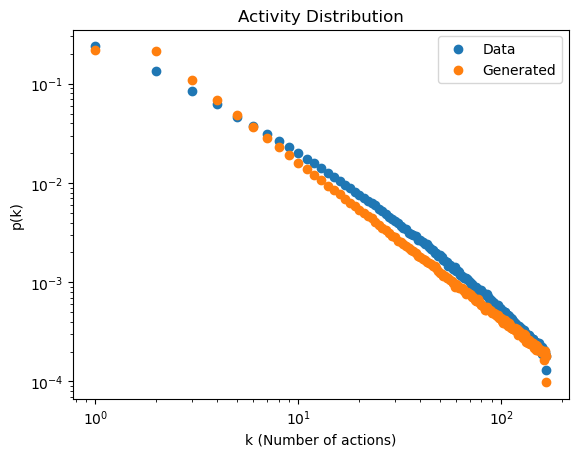

In [10]:
# https://mathworld.wolfram.com/RandomNumber.html
def gen_power_law(m, x_min, x_max):
    return ((x_max ** (m + 1) - x_min ** (m + 1)) * np.random.uniform(size=len(users)) + x_min ** (m + 1)) ** (1 / (m + 1))

hist = Counter(np.round(gen_power_law(popt[0], 1, np.max(activity_levels))))

x_new, y_new = zip(*hist.items())

x_new = np.array(x_new) 
y_new = np.array(y_new)
y_new = y_new / np.sum(y_new)

plt.scatter(x, y, label="Data")
plt.scatter(x_new, y_new, label="Generated")
plt.xlabel("k (Number of actions)")
plt.ylabel("p(k)")
plt.legend()
plt.loglog()
plt.title("Activity Distribution")
plt.show()

In [11]:
print(max(activity_levels))

167


## 5) Change log

Record updates so future changes are traceable.

- `2026-10-08`: Made small change to the way quotes are labeled from the Bluesky firehose since it was inaccurate.
- `2026-10-12`: Added function for generating activity levels